# Bank Failure Prediction (Liquidity & Solvency)

> **What it does:** predicts which U.S. banks will fail within the next year from their quarterly call reports, for every FDIC-insured bank since 2007. It trains on the 2007–2012 failure wave and tests out of time on 2013–2026, and checks whether the models would have flagged Silicon Valley Bank, Signature Bank and First Republic before March 2023.
> **Data:** quarterly financials of all FDIC-insured institutions and the FDIC failure list (FDIC BankFind Suite API, `api.fdic.gov`), 2007 Q1 onwards.
> **Methods:** CAMELS-style ratios (capital, asset quality, earnings, liquidity, funding structure, CRE concentration, growth); logistic regression; LightGBM with class weighting; a discrete-time hazard model (complementary log-log); out-of-time validation with ROC-AUC, PR-AUC, top-decile capture and calibration; TreeSHAP explanations; a case study of the 2023 failures.
> **Key output:** out-of-time discrimination by model; the drivers of failure risk; how early failures are flagged; and the 2023 case study showing what solvency ratios miss.

## 1. Why bank failure models matter for counterparty risk

A development bank deals with commercial banks every day: as swap counterparties, as custodians, as issuers of the bonds in its liquidity portfolio and as intermediaries for on-lending. A **bank counterparty early-warning model** ranks them by the risk of failure before ratings move.

U.S. data are unusually good for this: every insured bank files a quarterly call report, and the FDIC publishes every failure. The 2008–2012 wave (about 470 failures) is the training set. The test asks two questions:

1. Does a model fitted on the subprime-era failures still rank the banks that failed in 2013–2026?
2. Would it have seen the **2023 failures** coming? SVB, Signature and First Republic were well capitalised and profitable on paper. They failed through uninsured-deposit runs and unrealised losses on securities, not through bad loans.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

FDIC_API = "https://api.fdic.gov/banks"
FIRST_QUARTER, LAST_TRAIN_YEAR = "2007-03-31", 2012
HORIZON_Q = 4                     # predict failure within the next 4 quarters
LAG_Q = 1                         # call reports are published ~2 months after quarter end: skip one quarter
FIELDS = ["CERT", "REPDTE", "NAME", "STNAME", "ASSET", "EQ", "ROA", "NIMY", "EEFFR", "NCLNLSR", "NTLNLSR", "LNRESNCR",
          "RBC1AAJ", "RBCRWAJ", "DEP", "DEPUNA", "BRO", "LNLSNET", "SC", "CHBAL", "LNRECONS", "LNREMULT", "LNRENRES"]
CASE_STUDY = {24735: "Silicon Valley Bank", 57053: "Signature Bank", 59017: "First Republic Bank"}
SEED = 17

print(f"lightgbm {lgb.__version__} · statsmodels {sm.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · statsmodels 0.15.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

MODEL_COLORS = {"Logistic": PALETTE[0], "Discrete-time hazard": PALETTE[2], "LightGBM": PALETTE[1]}


def fdic_get(endpoint, **params):
    r = requests.get(f"{FDIC_API}/{endpoint}", params=params, headers=BROWSER_HEADERS, timeout=120)
    r.raise_for_status()
    return r.json()

## 3. Data: 78 quarters of call reports and the failure list

One API call per quarter returns every bank's ratios (amounts in $ thousands). Banks that report zero for a field that only larger banks report (estimated uninsured deposits, risk-based capital for banks under the community bank leverage ratio) are set to missing, not zero.

In [3]:
QUARTERS = pd.date_range(FIRST_QUARTER, pd.Timestamp.today() - pd.Timedelta(days=75), freq="QE")


def fetch_financials():
    parts = []
    for q in QUARTERS:
        d = fdic_get("financials", filters=f"REPDTE:{q:%Y%m%d}", limit=10_000, fields=",".join(FIELDS))
        parts.append(pd.DataFrame([x["data"] for x in d["data"]]))
        time.sleep(0.2)
    return pd.concat(parts, ignore_index=True)


def fetch_failures():
    d = fdic_get("failures", limit=10_000, fields="CERT,NAME,FAILDATE,QBFASSET,CITYST,RESTYPE,COST")
    return pd.DataFrame([x["data"] for x in d["data"]])


fin = cached("fdic_financials", fetch_financials, max_age_hours=24 * 30)
fail = cached("fdic_failures", fetch_failures, max_age_hours=24 * 7)
fin["date"] = pd.to_datetime(fin["REPDTE"], format="%Y%m%d")
fail["FAILDATE"] = pd.to_datetime(fail["FAILDATE"], format="%m/%d/%Y")
fail = fail[(fail["FAILDATE"] >= FIRST_QUARTER) & fail["RESTYPE"].eq("FAILURE")]
for c in ["DEPUNA", "RBCRWAJ"]:
    fin.loc[fin[c] <= 0, c] = np.nan
print(f"{len(fin):,} bank-quarters · {fin['CERT'].nunique():,} banks · {fin['date'].min():%Y-%m} → {fin['date'].max():%Y-%m} · "
      f"{len(fail)} failures since 2007")
fail.groupby(fail["FAILDATE"].dt.year).size().rename("failures").to_frame().T

487,729 bank-quarters · 9,150 banks · 2007-03 → 2026-06 · 551 failures since 2007


FAILDATE,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2019,2020,2023,2024,2025,2026
failures,2,25,140,157,92,51,24,18,8,5,8,4,4,5,2,2,4


## 4. Features and the target

| CAMELS area | Features |
|---|---|
| **C**apital | equity / assets, Tier 1 leverage ratio, total risk-based capital ratio |
| **A**sset quality | noncurrent loans / loans, net charge-offs / loans, reserves / noncurrent loans |
| **M**anagement / efficiency | efficiency ratio (non-interest expense / revenue) |
| **E**arnings | return on assets, net interest margin |
| **L**iquidity | cash / assets, securities / assets, loans / assets |
| **S**ensitivity and funding | uninsured deposits / deposits, brokered deposits / deposits, deposits / assets |
| Concentration and growth | construction and multifamily CRE / equity, nonfarm nonresidential CRE / equity; 1-year asset and deposit growth; log assets |

**Target:** the bank fails in quarters $t+1+\text{LAG}$ to $t+\text{LAG}+4$, i.e. within the year after its report is public. Bank-quarters after a failure are dropped.

In [4]:
f = fin.sort_values(["CERT", "date"]).copy()
num = lambda c: pd.to_numeric(f[c], errors="coerce")
A = num("ASSET").where(num("ASSET") > 0)
X = pd.DataFrame(index=f.index)
X["equity / assets %"] = num("EQ") / A * 100
X["Tier 1 leverage %"] = num("RBC1AAJ")
X["total RBC ratio %"] = num("RBCRWAJ")
X["noncurrent loans %"] = num("NCLNLSR")
X["net charge-offs %"] = num("NTLNLSR")
X["reserves / noncurrent %"] = num("LNRESNCR").clip(upper=1_000)
X["efficiency ratio %"] = num("EEFFR").clip(-50, 300)
X["ROA %"] = num("ROA")
X["NIM %"] = num("NIMY")
X["cash / assets %"] = num("CHBAL") / A * 100
X["securities / assets %"] = num("SC") / A * 100
X["loans / assets %"] = num("LNLSNET") / A * 100
X["uninsured / deposits %"] = num("DEPUNA") / num("DEP") * 100
X["brokered / deposits %"] = num("BRO") / num("DEP") * 100
X["deposits / assets %"] = num("DEP") / A * 100
X["construction+multifamily CRE / equity"] = (num("LNRECONS") + num("LNREMULT")) / num("EQ").where(num("EQ") > 0)
X["nonres. CRE / equity"] = num("LNRENRES") / num("EQ").where(num("EQ") > 0)
X["log assets"] = np.log(A)
X["asset growth 1y %"] = f.groupby("CERT")["ASSET"].transform(lambda s: pd.to_numeric(s, errors="coerce").pct_change(4)) * 100
X["deposit growth 1y %"] = f.groupby("CERT")["DEP"].transform(lambda s: pd.to_numeric(s, errors="coerce").pct_change(4)) * 100
for c in X.columns:
    lo, hi = X[c].quantile([0.005, 0.995])
    X[c] = X[c].clip(lo, hi)
FEATURES = list(X.columns)

fail_date = fail.drop_duplicates("CERT").set_index("CERT")["FAILDATE"]
f["fail_date"] = f["CERT"].map(fail_date)
q_to_fail = ((f["fail_date"].dt.to_period("Q") - f["date"].dt.to_period("Q")).apply(lambda p: p.n if pd.notna(p) else np.nan))
f["y"] = q_to_fail.between(1 + LAG_Q, LAG_Q + HORIZON_Q).astype(int)
keep = ~(q_to_fail <= LAG_Q)                                    # drop the quarters right before / after failure
full = pd.concat([f[["CERT", "NAME", "STNAME", "date", "y"]], X], axis=1)     # every bank-quarter, for scoring
panel = full[keep]
panel = panel[panel["date"] <= QUARTERS[-1 - HORIZON_Q - LAG_Q]]  # labels must be complete
train = panel[panel["date"].dt.year <= LAST_TRAIN_YEAR]
test = panel[panel["date"].dt.year > LAST_TRAIN_YEAR]
print(f"Train {train['date'].min():%Y-%m}–{train['date'].max():%Y-%m}: {len(train):,} bank-quarters, {train['y'].sum():,} positive "
      f"({train.loc[train['y'] == 1, 'CERT'].nunique()} failing banks) · Test {test['date'].min():%Y-%m}–{test['date'].max():%Y-%m}: "
      f"{len(test):,}, {test['y'].sum():,} positive ({test.loc[test['y'] == 1, 'CERT'].nunique()} banks)")
pd.DataFrame({"failed within a year (train)": train[train["y"] == 1][FEATURES].median(),
              "survived (train)": train[train["y"] == 0][FEATURES].median()}).round(2)

Train 2007-03–2012-12: 192,137 bank-quarters, 1,952 positive (496 failing banks) · Test 2013-03–2025-03: 273,028, 232 positive (66 banks)


,failed within a year (train),survived (train)
equity / assets %,4.95,10.23
Tier 1 leverage %,4.63,9.67
total RBC ratio %,7.57,15.29
noncurrent loans %,10.68,1.20
net charge-offs %,2.35,0.14
reserves / noncurrent %,30.75,82.09
efficiency ratio %,114.15,70.67
ROA %,-2.96,0.74
NIM %,2.89,3.79
cash / assets %,6.33,4.66


## 5. Three models

- **Logistic regression** on standardised ratios (median-imputed, with missing-value flags): the classic early-warning model of bank supervisors.
- **Discrete-time hazard:** a complementary log-log GLM on the same ratios plus quarter-of-year effects. It models the quarterly hazard of failure and gives the same ranking information as a Cox model on bank-quarter data.
- **LightGBM** with class weights for the 1-in-150 positive rate, missing values handled natively and shallow, regularised trees.

All three are fitted on 2007–2012 only and scored on every bank-quarter from 2013.

In [5]:
med = train[FEATURES].median()


flag_cols = [c + " missing" for c in FEATURES if train[c].isna().std() > 0]


def design(df):
    return pd.concat([df[FEATURES].fillna(med), df[FEATURES].isna().astype(float).add_suffix(" missing")[flag_cols]], axis=1)


Xtr, Xte = design(train), design(test)
models, scores = {}, {}
logit = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5_000, class_weight="balanced")).fit(Xtr, train["y"])
models["Logistic"] = logit
scores["Logistic"] = logit.predict_proba(Xte)[:, 1]

sc = StandardScaler().fit(Xtr)
Htr = sm.add_constant(pd.DataFrame(sc.transform(Xtr), columns=Xtr.columns, index=Xtr.index))
Hte = sm.add_constant(pd.DataFrame(sc.transform(Xte), columns=Xte.columns, index=Xte.index), has_constant="add")
hazard = sm.GLM(train["y"], Htr, family=sm.families.Binomial(link=sm.families.links.CLogLog())).fit_regularized(alpha=1e-4, L1_wt=0.0)
scores["Discrete-time hazard"] = np.clip(hazard.predict(Hte), 0, 1)

gbm = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=100, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, reg_lambda=5.0, scale_pos_weight=20, random_state=SEED, verbose=-1)
gbm.fit(train[FEATURES], train["y"])
models["LightGBM"] = gbm
scores["LightGBM"] = gbm.predict_proba(test[FEATURES])[:, 1]


def capture(y, s, top=0.10):
    cut = np.quantile(s, 1 - top)
    return y[s >= cut].sum() / y.sum()


y_te = test["y"].to_numpy()
evaluation = pd.DataFrame({m: {"ROC-AUC": roc_auc_score(y_te, s), "PR-AUC": average_precision_score(y_te, s),
                               "base rate %": y_te.mean() * 100, "top-decile capture %": capture(y_te, s) * 100,
                               "top-1% capture %": capture(y_te, s, 0.01) * 100} for m, s in scores.items()}).T
evaluation

,ROC-AUC,PR-AUC,base rate %,top-decile capture %,top-1% capture %
Logistic,0.93,0.22,0.08,84.91,72.84
Discrete-time hazard,0.93,0.18,0.08,84.48,73.28
LightGBM,0.95,0.25,0.08,87.50,76.29


### Lead time: how early are failing banks flagged?

For each bank that failed in the test period, its percentile rank among all banks is tracked over the eight quarters before failure. A bank is "flagged" when it enters the riskiest 5%.

In [6]:
test_scored = test[["CERT", "NAME", "date", "y"]].assign(**{m: s for m, s in scores.items()})
for m in scores:
    test_scored[f"{m} pct"] = test_scored.groupby("date")[m].rank(pct=True) * 100
failed_test = fail[fail["FAILDATE"].dt.year > LAST_TRAIN_YEAR].drop_duplicates("CERT").set_index("CERT")["FAILDATE"]
path = []
full_scores = panel[panel["date"].dt.year > LAST_TRAIN_YEAR - 1][["CERT", "date"] + FEATURES].copy()
full_scores["LightGBM"] = gbm.predict_proba(full_scores[FEATURES])[:, 1]
full_scores["pct"] = full_scores.groupby("date")["LightGBM"].rank(pct=True) * 100
for cert, fd in failed_test.items():
    g = full_scores[full_scores["CERT"] == cert]
    for _, r in g.iterrows():
        k = (fd.to_period("Q") - r["date"].to_period("Q")).n
        if 1 <= k <= 8:
            path.append({"CERT": cert, "quarters before failure": k, "percentile": r["pct"]})
path = pd.DataFrame(path)
lead = path.groupby("quarters before failure")["percentile"].agg(median="median", flagged_share=lambda p: (p >= 95).mean() * 100)
lead.round(1)

,median,flagged_share
quarters before failure,,
2,99.90,88.80
3,99.80,85.00
4,99.60,86.40
5,99.40,84.60
6,99.00,75.00
7,98.30,71.00
8,97.70,68.30


## 6. What drives the risk: TreeSHAP

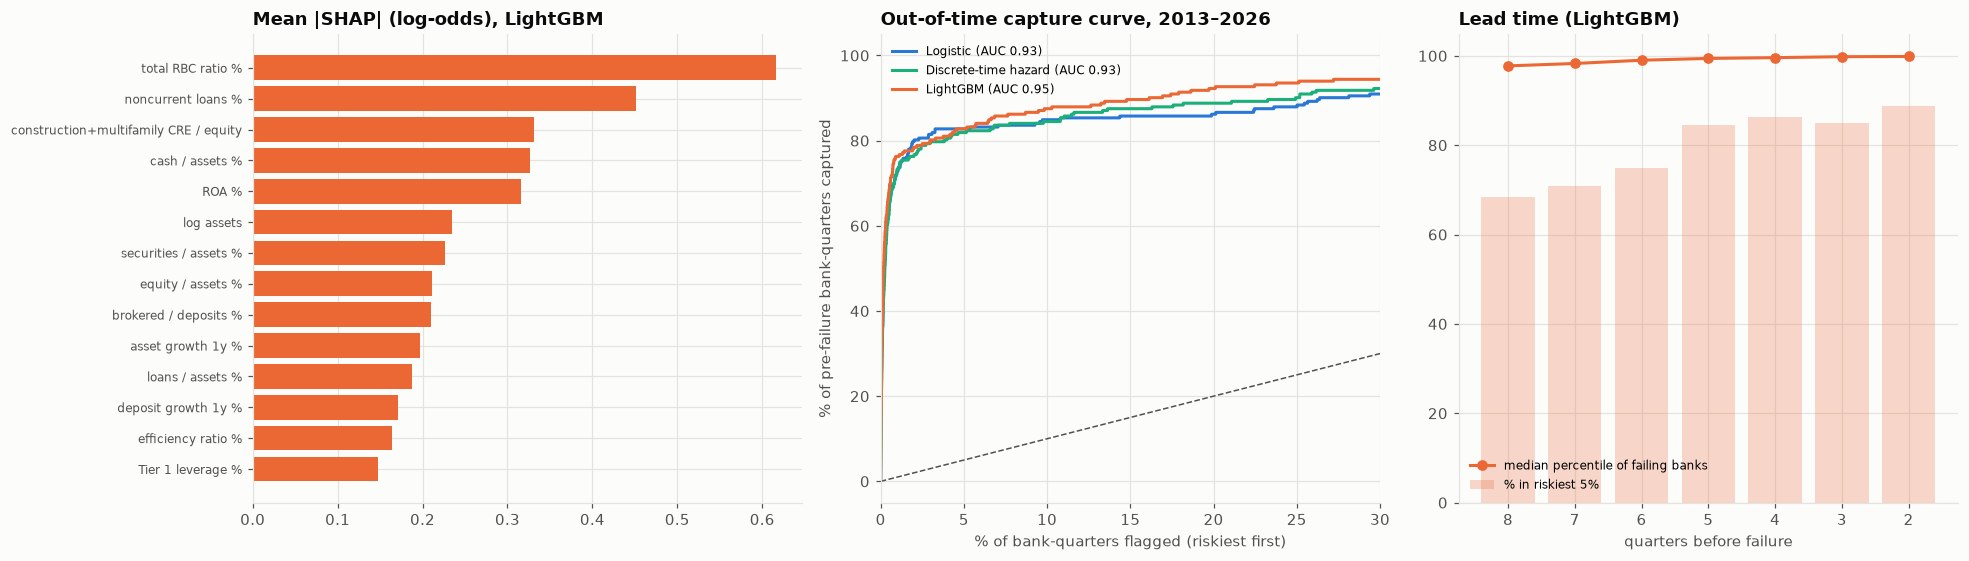

In [7]:
sample = test.sample(min(40_000, len(test)), random_state=SEED)
shap_vals = gbm.predict(sample[FEATURES], pred_contrib=True)[:, :-1]
shap_df = pd.DataFrame(shap_vals, columns=FEATURES, index=sample.index)
imp = shap_df.abs().mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
axes[0].barh(imp.index[-14:], imp.values[-14:], color=PALETTE[1])
axes[0].set_title("Mean |SHAP| (log-odds), LightGBM")
axes[0].tick_params(axis="y", labelsize=8)
ax = axes[1]
for m, s in scores.items():
    order = np.argsort(-s)
    ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, np.cumsum(y_te[order]) / y_te.sum() * 100, color=MODEL_COLORS[m],
            label=f"{m} (AUC {evaluation.loc[m, 'ROC-AUC']:.2f})")
ax.plot([0, 100], [0, 100], color=INK_2, ls="--", lw=1)
ax.set_xlim(0, 30)
ax.set_xlabel("% of bank-quarters flagged (riskiest first)")
ax.set_ylabel("% of pre-failure bank-quarters captured")
ax.set_title("Out-of-time capture curve, 2013–2026")
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(lead.index, lead["median"], "o-", color=PALETTE[1], label="median percentile of failing banks")
ax.bar(lead.index, lead["flagged_share"], color=PALETTE[1], alpha=0.25, label="% in riskiest 5%")
ax.invert_xaxis()
ax.set_xlabel("quarters before failure")
ax.set_title("Lead time (LightGBM)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_shap_capture_lead")
plt.show()

## 7. Case study: the 2023 failures

The three largest failures of 2023 are scored on their December 2022 call reports, the last ones public before the runs. Their percentile rank among all banks, the main ratios and the LightGBM drivers show what a solvency-oriented early-warning model can and cannot see.

In [8]:
q_case = pd.Timestamp("2022-12-31")
cs = full[full["date"] == q_case].copy()          # all banks reporting in Dec 2022, including those that failed in Q1 2023
cs["LightGBM"] = gbm.predict_proba(cs[FEATURES])[:, 1]
cs["Logistic"] = logit.predict_proba(design(cs))[:, 1]
for m in ["LightGBM", "Logistic"]:
    cs[f"{m} percentile"] = cs[m].rank(pct=True) * 100
big = cs[cs["log assets"] >= np.log(10e6)]                      # banks above $10bn (assets in $ thousands)
rows = []
for cert, name in CASE_STUDY.items():
    r = cs[cs["CERT"] == cert]
    if r.empty:
        continue
    r = r.iloc[0]
    contrib = pd.Series(gbm.predict(r[FEATURES].to_frame().T.astype(float), pred_contrib=True)[0][:-1], index=FEATURES)
    rows.append({"bank": name, "LightGBM percentile (all banks)": r["LightGBM percentile"],
                 "LightGBM rank among >$10bn banks": int((big["LightGBM"] > r["LightGBM"]).sum() + 1),
                 "Logistic percentile": r["Logistic percentile"], "equity / assets %": r["equity / assets %"],
                 "uninsured / deposits %": r["uninsured / deposits %"], "securities / assets %": r["securities / assets %"],
                 "asset growth 1y %": r["asset growth 1y %"], "noncurrent loans %": r["noncurrent loans %"],
                 "top risk drivers": ", ".join(contrib.sort_values(ascending=False).index[:3])})
case = pd.DataFrame(rows).set_index("bank")
print(f"Banks above $10bn in Dec 2022: {len(big)}; median uninsured share {big['uninsured / deposits %'].median():.0f}%")
case.round(1).T

Banks above $10bn in Dec 2022: 162; median uninsured share 42%


bank,Silicon Valley Bank,Signature Bank,First Republic Bank
LightGBM percentile (all banks),28.10,96.70,91.10
LightGBM rank among >$10bn banks,138,6,24
Logistic percentile,22.00,81.90,80.30
equity / assets %,7.40,7.30,8.20
uninsured / deposits %,86.40,89.70,67.70
securities / assets %,56.10,23.70,14.90
asset growth 1y %,0.20,-6.80,17.40
noncurrent loans %,0.20,0.30,0.10
top risk drivers,"efficiency ratio %, Tier 1 leverage %, nonres....","construction+multifamily CRE / equity, log ass...","construction+multifamily CRE / equity, log ass..."


## 8. Reading the results and limitations

All FDIC-insured banks, 2007 Q1 – 2026 Q2 (488,000 bank-quarters, 9,150 banks, 551 failures):

- **The failure wave is very learnable.** Banks that failed within a year in 2007–2012 looked nothing like survivors: median equity of 5% of assets (vs 10%), noncurrent loans of 11% (vs 1.2%), ROA of −3% (vs +0.7%), an efficiency ratio of 114% and construction and multifamily CRE at 3.8 times equity (vs 0.5). These are classic CAMELS signals.
- **It also transfers out of time.** Trained on 2007–2012 and tested on 2013–2025 (66 failing banks), LightGBM reaches a ROC-AUC of **0.95**; logistic regression and the discrete-time hazard model reach 0.93. The riskiest 10% of bank-quarters contain 85–88% of the pre-failure quarters, and the riskiest 1% contain 73–76%. PR-AUC (0.18–0.25 against a base rate of 0.08%) is the more honest measure for a rare event: about one in five or one in four flagged quarters is a real pre-failure quarter.
- **Lead time is long for small-bank failures.** Eight quarters before failure, a failing bank already sits at the 98th percentile of risk on median, and 68% are in the riskiest 5%. Two quarters before, 89% are. Most U.S. failures are slow-motion solvency failures that the call report shows clearly.
- **What drives the score.** In TreeSHAP order: total risk-based capital, noncurrent loans, construction and multifamily CRE concentration, cash, ROA, size and securities holdings. These are capital, asset quality, concentration and earnings, exactly the supervisory playbook.
- **The 2023 failures expose the limit.** On their December 2022 reports:
  - **Signature Bank** was flagged: 97th percentile overall and 6th riskiest of 162 banks above $10bn. The drivers were its multifamily CRE concentration and its size.
  - **First Republic** was at the 91st percentile (24th among large banks), also through CRE concentration.
  - **Silicon Valley Bank** was **not** flagged: 28th percentile, 138th of 162. Its noncurrent loans were 0.2%, its leverage normal and its earnings positive. What killed it was invisible to a model trained on 2008: 86% uninsured deposits, 56% of assets in securities with large unrealised losses, and a concentrated depositor base. In the training data, failing banks actually had a *lower* uninsured share than survivors (12% vs 19%), so the model learned that uninsured deposits are not a risk factor.
- **For a counterparty early-warning system,** this argues for two layers: a solvency model like this one, which works well for the typical failure, and an explicit **liquidity and funding overlay** with uninsured-deposit concentration, deposit growth, held-to-maturity losses against capital, and market signals. Those were the warning signs of 2023.

**Limitations**

- Call-report ratios only. No market data (equity prices, CDS), supervisory ratings, or unrealised securities losses (AOCI and HTM fair values), which would have mattered for SVB.
- 66 failing banks in the test period, mostly small. Rankings among large banks rest on very few events.
- Uninsured deposits are only reported by banks above $1bn of assets, and the CBLR election removed risk-based ratios for many small banks after 2020. Both are handled as missing, which LightGBM uses natively.

In [9]:
evaluation.to_csv(OUT_DIR / "out_of_time_evaluation.csv")
lead.to_csv(OUT_DIR / "lead_time.csv")
case.to_csv(OUT_DIR / "case_study_2023.csv")
imp.sort_values(ascending=False).rename("mean |SHAP|").to_csv(OUT_DIR / "shap_importance.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_shap_capture_lead.png, case_study_2023.csv, lead_time.csv, out_of_time_evaluation.csv, shap_importance.csv
